# 13 — Preprocessing sMRI: dari Permukaan Korteks DCAN sampai Morfometri per Parcel

Notebook ini menjelaskan, langkah demi langkah, bagaimana data sMRI setiap subjek diubah menjadi fitur struktur otak yang dipakai skenario S2–S4.

| | |
| :--- | :--- |
| **Masukan** | `data/processed/kohort_dcan.csv` (1.638 subjek) · berkas sMRI DCAN setiap subjek (`data/raw_dcan/`, lihat notebook 02) |
| **Keluaran** (sudah dibuat oleh notebook 12, **tidak ditimpa** di sini) | `data/processed/fitur_smri_dcan/fitur_smri_dcan.npz`: `morfo_hcp2016` (5 morfometri per parcel) |
| **Dipakai oleh** | S2–S4 (morfometri di fitur simpul graf) |

### Alur

```
permukaan korteks DCAN (±32 ribu titik per belahan otak)
   │  1. 5 fitur per titik: ketebalan, kelengkungan, kedalaman sulkus, luas, volume
   │  2. kelompokkan titik ke 360 parcel HCP (parcel yang sama dengan rs-fMRI)
   ▼
   3. MORFOMETRI per parcel (360 × 5)  → fitur simpul graf S2–S4
```

Setiap langkah ditunjukkan pada **satu subjek contoh** (Caltech_0051457, sama dengan notebook 11), lalu hasilnya **dihitung ulang dan dicocokkan** dengan berkas yang dipakai S2–S4. Kalau tidak cocok, notebook berhenti dengan error. Lama proses ±1 menit.

> **Catatan perubahan (14 Okt 2026):** versi sebelumnya juga menjelaskan MIND (kemiripan struktur antar parcel) dan kopling struktur–fungsi, yang hanya dipakai S4 lama (sudah diarsipkan). Kedua bagian itu dihapus; S4 sekarang = S3 + optimasi hyperparameter (notebook 19).

## Persiapan

In [1]:
import glob
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
from nilearn import plotting
from IPython.display import display
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
while not (ROOT / "data").exists():
    ROOT = ROOT.parent
PROC = ROOT / "data" / "processed"
FIG_DIR = ROOT / "result" / "figure"
FIG_DIR.mkdir(parents=True, exist_ok=True)
STRUKTUR = {"CIFTI_STRUCTURE_CORTEX_LEFT": "L", "CIFTI_STRUCTURE_CORTEX_RIGHT": "R"}
NAMA_FITUR = ["ketebalan (mm)", "kelengkungan", "kedalaman sulkus", "luas (mm²)", "volume GM (mm³)"]

kohort = pd.read_csv(PROC / "kohort_dcan.csv")
F = np.load(PROC / "fitur_smri_dcan" / "fitur_smri_dcan.npz", allow_pickle=True)
assert list(F["sub"]) == list(kohort["sub"]), "urutan subjek fitur sMRI tidak sama dengan kohort"
CONTOH = 0
r = kohort.iloc[CONTOH]
D = ROOT / "data" / "raw_dcan" / r["dataset"] / r["sub"]
cari = lambda pola: next(iter(glob.glob(str(D / pola))))
print(f"Subjek contoh: {r['FILE_ID']} | {'ASD' if r['label'] else 'Kontrol'} | {r['situs']} | usia {r['usia']:.1f}")

Subjek contoh: Caltech_0051457 | ASD | CALTECH | usia 22.9


## 1. Lima Fitur di Setiap Titik Permukaan Korteks

Pipeline DCAN merekonstruksi permukaan korteks sebagai *mesh*: ±32 ribu titik per belahan otak yang dihubungkan segitiga (lihat notebook 02). Di setiap titik ada 5 nilai:

| Fitur | Asal | Arti |
| :--- | :--- | :--- |
| Ketebalan | berkas `thickness` DCAN | tebal korteks (mm) |
| Kelengkungan | berkas `curv` DCAN | seberapa melengkung permukaan |
| Kedalaman sulkus | berkas `sulc` DCAN | positif di lipatan dalam, negatif di puncak lipatan |
| **Luas** | **dihitung** dari *mesh* ruang asli subjek | sepertiga luas setiap segitiga di sekitar titik itu (mm²) |
| **Volume** | **dihitung** = ketebalan × luas | volume materi abu-abu di sekitar titik (mm³) |

Titik di **dinding medial** (bagian tengah otak yang bukan korteks) tidak punya nilai, dan tidak dipakai.

In [2]:
def ke_32k(img):
    """dscalar → dict belahan: array 32.492 titik (NaN untuk titik dinding medial)."""
    x, ax = img.get_fdata()[0], img.header.get_axis(1)
    hasil = {}
    for s, h in STRUKTUR.items():
        m = ax.name == s
        arr = np.full(ax.nvertices[s], np.nan)
        arr[ax.vertex[m]] = x[m]
        hasil[h] = arr
    return hasil

def luas_titik(berkas_gii):
    g = nib.load(berkas_gii)
    v, t = g.agg_data("NIFTI_INTENT_POINTSET").astype(np.float64), g.agg_data("NIFTI_INTENT_TRIANGLE")
    a = 0.5 * np.linalg.norm(np.cross(v[t[:, 1]] - v[t[:, 0]], v[t[:, 2]] - v[t[:, 0]]), axis=1)
    luas = np.zeros(len(v))
    np.add.at(luas, t.ravel(), np.repeat(a / 3.0, 3))
    return luas

ket = ke_32k(nib.load(cari("*_space-fsLR32k_thickness.dscalar.nii")))
kel = ke_32k(nib.load(cari("*_space-fsLR32k_curv.dscalar.nii")))
sul = ke_32k(nib.load(cari("*_space-fsLR32k_sulc.dscalar.nii")))
luas = {h: luas_titik(cari(f"*_hemi-{h}_space-T1w_mesh-fsLR32k_midthickness.surf.gii")) for h in "LR"}
TITIK = {h: np.column_stack([ket[h], kel[h], sul[h], luas[h], ket[h] * luas[h]]) for h in "LR"}     # (32.492, 5) per belahan

semua = np.vstack([TITIK[h][np.isfinite(TITIK[h]).all(1)] for h in "LR"])
display(pd.DataFrame({"Fitur": NAMA_FITUR, "Rata-rata per titik": semua.mean(0), "SD": semua.std(0),
                      "Total seluruh korteks": [np.nan, np.nan, np.nan, semua[:, 3].sum(), semua[:, 4].sum()]})
        .round(3).style.set_caption(f"{len(semua):,} titik korteks (kedua belahan) | luas total {semua[:, 3].sum() / 100:.0f} cm²"))

,Fitur,Rata-rata per titik,SD,Total seluruh korteks
0,ketebalan (mm),2.512000,0.765000,nan
1,kelengkungan,0.015000,0.155000,nan
2,kedalaman sulkus,-0.056000,0.613000,nan
3,luas (mm²),3.827000,1.546000,227366.544000
4,volume GM (mm³),9.760000,5.478000,579832.146000


## 2. Mengelompokkan Titik ke 360 Parcel

Titik-titik dikelompokkan ke **360 parcel korteks atlas HCP**, yaitu parcel yang **sama persis** dengan *time series* rs-fMRI. Daftar titik setiap parcel dibaca dari berkas *time series* fMRI subjek. Karena parcel didefinisikan pada templat permukaan yang sama untuk semua subjek, titik ke-*i* di semua subjek berada di lokasi anatomis yang setara.

Dengan begitu, **setiap parcel punya informasi fungsi (FC) dan struktur (morfometri) dari wilayah otak yang sama**, dan inilah dasar simpul graf multimodal di S2–S4.

,,Nilai
0,Parcel korteks HCP,360
1,Titik per parcel (median),132
2,Titik per parcel (min–maks),32–841


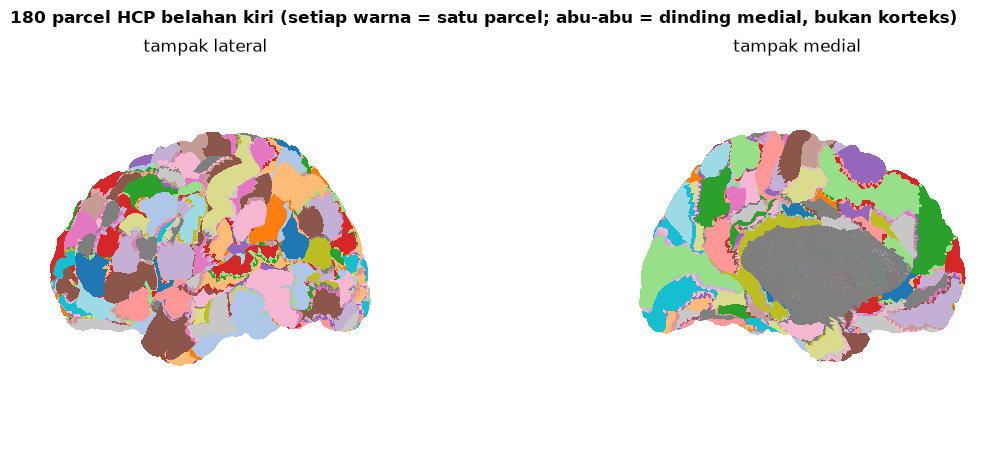

In [3]:
ax_parcel = nib.load(ROOT / r["berkas_hcp2016"]).header.get_axis(1)
PARCEL = [(nama, {STRUKTUR[s]: np.asarray(v) for s, v in verts.items() if s in STRUKTUR})
          for nama, verts in zip(ax_parcel.name, ax_parcel.vertices) if any(s in STRUKTUR for s in verts)]
NAMA_PARCEL = [p[0] for p in PARCEL]
assert NAMA_PARCEL == list(F["parcel_hcp2016"]), "urutan parcel berbeda dengan berkas fitur"
n_titik = [sum(len(v) for v in p[1].values()) for p in PARCEL]
display(pd.DataFrame({"": ["Parcel korteks HCP", "Titik per parcel (median)", "Titik per parcel (min–maks)"],
                      "Nilai": [len(PARCEL), int(np.median(n_titik)), f"{min(n_titik)}–{max(n_titik)}"]}))

warna_acak = np.random.default_rng(0).permutation(len(PARCEL)).astype(float)
label_L = np.full(32492, np.nan)                      # NaN = dinding medial (tampil abu-abu)
for i, (_, idx) in enumerate(PARCEL):
    if "L" in idx:
        label_L[idx["L"]] = warna_acak[i]
mesh = nib.load(cari("*_hemi-L_space-T1w_mesh-fsLR32k_midthickness.surf.gii"))
koord, segitiga = mesh.agg_data("NIFTI_INTENT_POINTSET"), mesh.agg_data("NIFTI_INTENT_TRIANGLE")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), subplot_kw={"projection": "3d"})
for ax, tampak in zip(axes, ["lateral", "medial"]):
    plotting.plot_surf_stat_map((koord, segitiga), label_L, hemi="left", view=tampak, cmap="tab20", colorbar=False,
                                axes=ax, figure=fig, title=f"tampak {tampak}")
fig.suptitle("180 parcel HCP belahan kiri (setiap warna = satu parcel; abu-abu = dinding medial, bukan korteks)", fontweight="bold")
fig.savefig(FIG_DIR / "21c_1_parcel_hcp.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Morfometri per Parcel (360 × 5)

Titik-titik setiap parcel diringkas menjadi 5 angka:

| Fitur parcel | Cara meringkas titik |
| :--- | :--- |
| luas | **dijumlah** |
| volume GM | **dijumlah** |
| ketebalan | rata-rata **dibobot luas** (titik yang mewakili permukaan lebih luas berbobot lebih besar) |
| kelengkungan | rata-rata |
| kedalaman sulkus | rata-rata |

Sel ini menghitung ulang morfometri subjek contoh dan mencocokkannya dengan `morfo_hcp2016` di berkas fitur.

,luas (mm²),volume GM (mm³),ketebalan (mm),kelengkungan,kedalaman sulkus
R_V1_ROI,3648.295898,5764.689941,1.580000,0.042000,-0.015000
R_MST_ROI,326.859985,768.419006,2.351000,-0.062000,-0.628000
R_V6_ROI,483.125000,889.859009,1.842000,-0.025000,-0.435000
R_V2_ROI,2929.934082,6267.136230,2.139000,0.030000,0.047000
R_V3_ROI,1921.444946,4154.360840,2.162000,0.028000,-0.107000


Verifikasi morfometri vs berkas fitur: selisih maksimum 0.00e+00 → COCOK


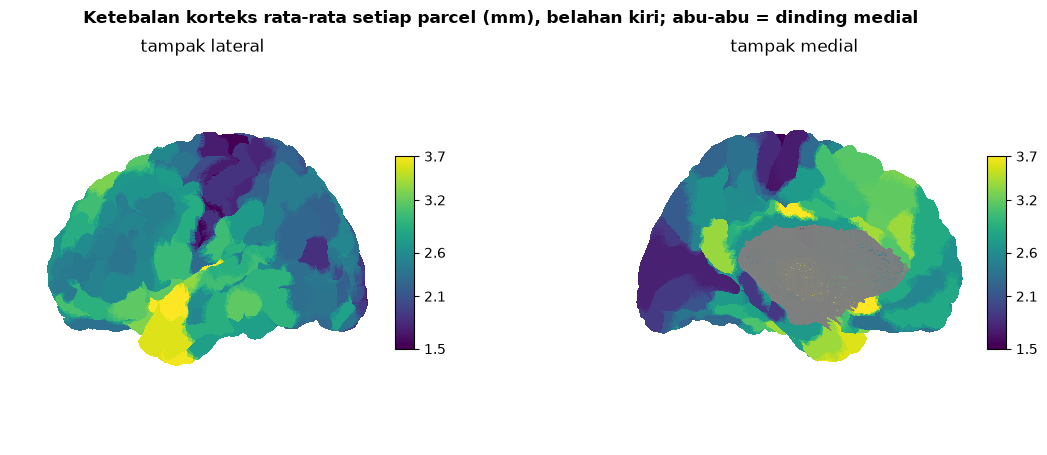

In [4]:
def morfometri(titik, parcel):
    hasil = []
    for _, idx in parcel:
        X = np.vstack([titik[h][i] for h, i in idx.items()])
        X = X[np.isfinite(X).all(1)]
        w = X[:, 3] / X[:, 3].sum()
        hasil.append([X[:, 3].sum(), X[:, 4].sum(), (w * X[:, 0]).sum(), X[:, 1].mean(), X[:, 2].mean()])
    return np.asarray(hasil, dtype=np.float32)

MORFO = morfometri(TITIK, PARCEL)
simpan = F["morfo_hcp2016"][CONTOH]
cocok = np.allclose(MORFO, simpan, rtol=1e-5, atol=1e-5)
display(pd.DataFrame(MORFO[:5], columns=["luas (mm²)", "volume GM (mm³)", "ketebalan (mm)", "kelengkungan", "kedalaman sulkus"],
                     index=NAMA_PARCEL[:5]).round(3).style.set_caption("5 parcel pertama subjek contoh"))
print(f"Verifikasi morfometri vs berkas fitur: selisih maksimum {np.abs(MORFO - simpan).max():.2e} → {'COCOK' if cocok else 'TIDAK COCOK'}")
assert cocok

peta_ketebalan = np.full(32492, np.nan)
for (nama, idx), m in zip(PARCEL, MORFO):
    if "L" in idx:
        peta_ketebalan[idx["L"]] = m[2]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), subplot_kw={"projection": "3d"})
for ax, tampak in zip(axes, ["lateral", "medial"]):
    plotting.plot_surf_stat_map((koord, segitiga), peta_ketebalan, hemi="left", view=tampak,
                                cmap="viridis", vmin=np.nanpercentile(peta_ketebalan, 2), vmax=np.nanpercentile(peta_ketebalan, 98),
                                colorbar=True, axes=ax, figure=fig, title=f"tampak {tampak}")
fig.suptitle("Ketebalan korteks rata-rata setiap parcel (mm), belahan kiri; abu-abu = dinding medial", fontweight="bold")
fig.savefig(FIG_DIR / "21c_2_ketebalan_per_parcel.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Pemeriksaan Seluruh Berkas Fitur sMRI

Berkas `fitur_smri_dcan.npz` juga berisi fitur atlas Gordon (`*_gordon2014`) dan volume dari segmentasi (`seg_mm3`). Fitur-fitur itu hanya dipakai bangku uji sMRI (notebook 24, di arsip), bukan oleh skenario S1–S4.

In [5]:
baris = []
for kunci, bentuk, dipakai in [("morfo_hcp2016", (len(kohort), 360, 5), "S2–S4: fitur simpul graf")]:
    V = F[kunci]
    baris.append({"Fitur": kunci, "Bentuk": str(V.shape), "Bentuk benar": V.shape == bentuk,
                  "Semua nilai finit": bool(np.isfinite(V).all()), "Dipakai oleh": dipakai})
tabel = pd.DataFrame(baris)
display(tabel.style.set_caption("Fitur sMRI yang dipakai skenario (urutan subjek = kohort_dcan.csv)"))
assert tabel["Bentuk benar"].all() and tabel["Semua nilai finit"].all()

,Fitur,Bentuk,Bentuk benar,Semua nilai finit,Dipakai oleh
0,morfo_hcp2016,"(1638, 360, 5)",True,True,S2–S4: fitur simpul graf


## 5. Ringkasan

| Langkah | Masukan → keluaran | Dipakai di |
| :--- | :--- | :--- |
| 1. 5 fitur per titik | berkas permukaan DCAN → ±59 ribu titik × 5 | – |
| 2. Titik → parcel | 360 parcel HCP (sama dengan rs-fMRI) | – |
| 3. Morfometri | 360 parcel × 5 (luas, volume, ketebalan, kelengkungan, sulkus) | fitur simpul S2–S4 |
| 4. Pemeriksaan | 1.638 subjek, semua nilai finit | – |

Semua hasil yang dihitung ulang di notebook ini **identik** dengan berkas yang dipakai skenario S2–S4.

**Langkah berikutnya:** notebook 14 (baseline Logistic Regression), lalu skenario S1–S4 (notebook 16–19).